# Weekly report: recap + next-opponent preview

Set `TEAM`, `SEASON` and (optionally) `WEEK` in the parameters cell, then **Run All**.
`WEEK = None` picks the team's most recent completed regular-season game.

Each section reads a `sql/Queries/weekly_*.sql` file. The notebook overwrites the
values in each file's `params` CTE, so the same files also run on their own in a SQL editor.

Refresh the data first after a game week: `python src\refresh.py`.

| Section | Query |
|---|---|
| Season so far | `weekly_season_so_far.sql` |
| Recap: box score vs. season average | `weekly_recap_box.sql` |
| Recap: drive chart + drive list | `weekly_recap_drives.sql` |
| Recap: efficiency by quarter | `weekly_recap_quarters.sql` |
| Preview: next game + line | `weekly_preview_game.sql` |
| Preview: matchup with FBS ranks | `weekly_preview_matchup.sql` |

In [1]:
import os
import re
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from dotenv import load_dotenv
from sqlalchemy import create_engine
from IPython.display import display, Markdown

# project root = the folder containing .env (works from notebooks/ or the root)
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / ".env").exists())
load_dotenv(ROOT / ".env")

engine = create_engine(
    f"postgresql+psycopg2://{os.environ['POSTGRES_USER']}:{os.environ['POSTGRES_PASSWORD']}"
    f"@localhost:5432/{os.environ['POSTGRES_DB']}"
)

def sql_literal(value):
    if isinstance(value, str):
        return "'" + value.replace("'", "''") + "'::text"
    return str(int(value))

def read_query(name, **params):
    """Run a sql/Queries file. Keyword arguments replace the values in its `params` CTE."""
    sql = (ROOT / "sql" / "Queries" / name).read_text()
    if params:
        cols = ", ".join(f"{sql_literal(v)} AS {k}" for k, v in params.items())
        sql, n = re.subn(r"params AS \(\s*SELECT .*?\n\)", f"params AS (\n    SELECT {cols}\n)",
                         sql, count=1, flags=re.S)
        if n != 1:
            raise ValueError(f"{name}: no params CTE to replace")
    # "%" doubled because psycopg2 treats it as a parameter marker
    return pd.read_sql(sql.replace("%", "%%"), engine)

# chart colors: the team is always blue, the opponent always orange
BLUE, ORANGE = '#2a78d6', '#eb6834'
SURFACE, INK, INK_2, MUTED = '#fcfcfb', '#0b0b0b', '#52514e', '#b8b6ae'
plt.rcParams.update({
    'figure.facecolor': SURFACE, 'axes.facecolor': SURFACE,
    'axes.edgecolor': MUTED, 'axes.labelcolor': INK_2,
    'xtick.color': INK_2, 'ytick.color': INK_2,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.titlecolor': INK, 'axes.titlesize': 13, 'axes.titleweight': 'bold',
})

## Parameters

In [2]:
TEAM   = "Auburn"
SEASON = 2026
WEEK   = None    # None = the team's most recent completed regular-season game

if WEEK is None:
    WEEK = int(pd.read_sql(
        """SELECT max(week) AS week FROM core.team_games
           WHERE team = %(team)s AND season = %(season)s AND season_type = 'regular'""",
        engine, params={"team": TEAM, "season": SEASON},
    ).iloc[0, 0])

P = dict(team=TEAM, season=SEASON, week=WEEK)
print(f"{TEAM} {SEASON}, recap of week {WEEK}")

Auburn 2026, recap of week 5


## Season so far

In [3]:
season = read_query("weekly_season_so_far.sql", **P)

wins = (season["result"] == "W").sum()
covers = (season["ats"] == "covered").sum()
lines = season["ats"].notna().sum()
display(Markdown(f"**{TEAM}: {wins}-{len(season) - wins}**, {covers}-{lines - covers} against the spread"))
season

**Auburn: 3-2**, 1-4 against the spread

,week,game_date,site,opponent,result,score,margin,team_spread,ats,total_yards,opp_total_yards,off_ppa,def_ppa,turnovers,takeaways
0,1,2026-09-05,vs (N),Baylor,W,17-16,1,-6.50,missed,389,436,-0.044,-0.006,3,2
1,2,2026-09-12,vs,Southern Miss,W,43-8,35,-32.75,covered,610,221,0.343,-0.193,1,2
2,3,2026-09-19,vs,Florida,L,39-44,-5,2.50,missed,373,495,0.182,0.329,1,1
3,4,2026-09-26,vs,Vanderbilt,W,21-15,6,-10.00,missed,279,311,0.020,-0.042,1,1
4,5,2026-10-03,at,Tennessee,L,14-24,-10,6.25,missed,345,323,-0.120,0.023,3,2


## Recap

In [4]:
box = read_query("weekly_recap_box.sql", **P)
OPP = box["opponent"].iloc[0]
last = season[season["week"] == WEEK].iloc[0]
display(Markdown(f"### Week {WEEK}: {last['result']} {last['score']} {last['site']} {OPP}"))

# compare the team's game to its average coming in
def vs_usual(r):
    if pd.isna(r["team_avg_before"]) or r["team_value"] == r["team_avg_before"]:
        return ""
    better = (r["team_value"] > r["team_avg_before"]) == r["higher_is_better"]
    return "better" if better else "worse"

box_view = box.assign(vs_usual=box.apply(vs_usual, axis=1)).set_index("metric")[
    ["team_value", "opp_value", "team_avg_before", "vs_usual"]
].rename(columns={"team_value": TEAM, "opp_value": OPP,
                  "team_avg_before": f"{TEAM} avg coming in", "vs_usual": "vs. usual"})
box_view.round(2)

### Week 5: L 14-24 at Tennessee

,Auburn,Tennessee,Auburn avg coming in,vs. usual
metric,,,,
Points,14.00,24.00,30.00,worse
Total yards,345.00,323.00,412.75,worse
Yards per play,5.31,4.82,5.81,worse
Passing yards,159.00,86.00,234.25,worse
Rushing yards,186.00,237.00,178.50,better
Yards per rush,5.81,4.84,4.64,better
3rd down conversion,0.36,0.21,0.50,worse
Turnovers,3.00,2.00,1.50,worse
Penalty yards,94.00,30.00,57.25,worse


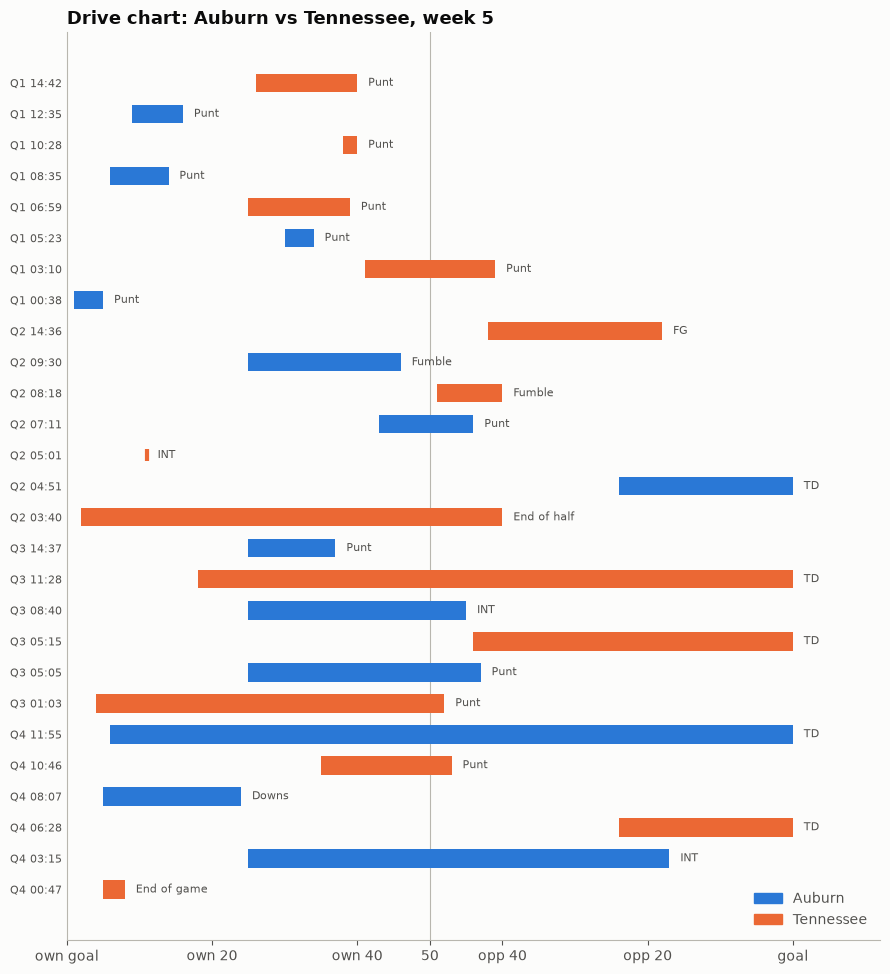

In [5]:
# drive chart: each bar is a drive, from where it started to the spot of its last snap
# (TD drives run to the goal line), in the offense's direction
drives = read_query("weekly_recap_drives.sql", **P)

RESULT_LABELS = {"TD": "TD", "FG": "FG", "MISSED FG": "Missed FG", "PUNT": "Punt", "INT": "INT",
                 "FUMBLE": "Fumble", "DOWNS": "Downs", "SAFETY": "Safety",
                 "END OF HALF": "End of half", "END OF GAME": "End of game", "OTHER": "Other"}

fig, ax = plt.subplots(figsize=(9, 0.32 * len(drives) + 1.2))
for _, d in drives.iterrows():
    color = BLUE if d["is_team"] else ORANGE
    start, end = d["start_yards_from_own_goal"], d["end_yards_from_own_goal"]
    if abs(end - start) < 1:   # drive ended where it started (e.g. a 1st-play turnover)
        ax.plot(start, d["drive_order"], marker="|", markersize=9, markeredgewidth=3, color=color)
    else:
        ax.barh(d["drive_order"], end - start, left=start, height=0.6, color=color)
    ax.text(max(start, end) + 1.5, d["drive_order"], RESULT_LABELS.get(d["result"], d["result"]),
            va="center", fontsize=8, color=INK_2)

ax.axvline(50, color=MUTED, linewidth=0.8, zorder=0)
ax.set_xlim(0, 112)
ax.set_xticks([0, 20, 40, 50, 60, 80, 100],
              ["own goal", "own 20", "own 40", "50", "opp 40", "opp 20", "goal"])
ax.set_yticks(drives["drive_order"],
              [f"Q{q} {c}" if isinstance(c, str) else f"OT{q - 4}"
               for q, c in zip(drives["quarter"], drives["clock"])],
              fontsize=8)
ax.invert_yaxis()
ax.tick_params(axis="y", length=0)
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=BLUE), plt.Rectangle((0, 0), 1, 1, color=ORANGE)],
          labels=[TEAM, OPP], frameon=False, loc="lower right", labelcolor=INK_2)
ax.set_title(f"Drive chart: {TEAM} vs {OPP}, week {WEEK}", loc="left")
plt.tight_layout()
plt.show()

In [6]:
drives.drop(columns=["drive_order", "is_team", "start_yards_from_own_goal", "end_yards_from_own_goal"])

,offense,quarter,clock,start,plays,yards,result,lead_before,third_downs,ppa_total
0,Tennessee,1,14:42,own 26,5,14,PUNT,0,0/1,-1.01
1,Auburn,1,12:35,own 9,3,12,PUNT,0,0/1,-0.16
2,Tennessee,1,10:28,own 38,3,2,PUNT,0,0/1,-2.02
3,Auburn,1,08:35,own 6,3,8,PUNT,0,0/1,-0.16
4,Tennessee,1,06:59,own 39,3,-14,PUNT,0,0/1,-2.53
5,Auburn,1,05:23,own 34,3,1,PUNT,0,0/1,-1.18
6,Tennessee,1,03:10,own 41,5,28,PUNT,0,0/1,0.24
7,Auburn,1,00:38,own 1,3,4,PUNT,0,0/1,-0.35
8,Tennessee,2,14:36,opp 42,9,24,FG,0,0/2,-1.25
9,Auburn,2,09:30,own 25,4,24,FUMBLE,-3,0/1,-4.16


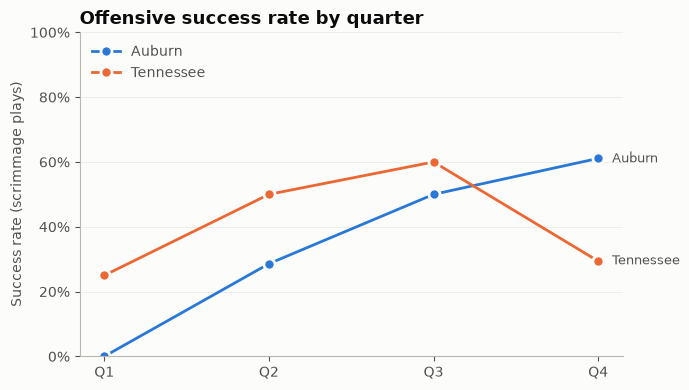

plays  yards_per_play  success_rate  ppa_per_play  \
offense   quarter                                                      
Auburn    Q1          11            2.27         0.000        -0.159   
          Q2          14            4.36         0.286        -0.217   
          Q3          22            3.77         0.500        -0.222   
          Q4          18            9.78         0.611         0.105   
Tennessee Q1          16            1.88         0.250        -0.332   
          Q2          24            3.96         0.500        -0.145   
          Q3          10           13.10         0.600         0.897   
          Q4          17            3.94         0.294         0.071   

                   pass_rate  explosive_plays  
offense   quarter                              
Auburn    Q1           0.455                0  
          Q2           0.643                0  
          Q3           0.591                1  
          Q4           0.556                2  
Tennessee Q1           0.500                0  
          Q2           0.333                0  
          Q3           0.100                3  
          Q4           0.235                0

In [7]:
# efficiency by quarter: success rate, both offenses
quarters = read_query("weekly_recap_quarters.sql", **P)

fig, ax = plt.subplots(figsize=(7, 4))
for is_team, color in [(True, BLUE), (False, ORANGE)]:
    q = quarters[quarters["is_team"] == is_team]
    name = q["offense"].iloc[0]
    ax.plot(q["quarter"], q["success_rate"], color=color, linewidth=2, marker="o", markersize=8,
            markeredgecolor=SURFACE, markeredgewidth=2, label=name)
    ax.annotate(name, (len(q) - 1, q["success_rate"].iloc[-1]),
                xytext=(10, 0), textcoords="offset points", va="center", color=INK_2, fontsize=9)

ax.set_ylim(0, 1)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_ylabel("Success rate (scrimmage plays)")
ax.grid(axis="y", color=MUTED, alpha=0.3, linewidth=0.5)
ax.legend(frameon=False, loc="upper left", labelcolor=INK_2)
ax.set_title("Offensive success rate by quarter", loc="left")
plt.tight_layout()
plt.show()

quarters.drop(columns="is_team").set_index(["offense", "quarter"])

## Preview

In [8]:
game = read_query("weekly_preview_game.sql", **P)

if game.empty:
    NEXT_OPP = None
    display(Markdown(f"No games left on {TEAM}'s {SEASON} schedule."))
else:
    g = game.iloc[0]
    NEXT_OPP = g["opponent"]
    where = {"home": "vs", "away": "at", "neutral": "vs (neutral site)"}[g["site"]]
    if pd.isna(g["team_spread"]):
        line = "no line yet"
    else:
        line = f"{TEAM} {g['team_spread']:+g}, over/under {g['over_under']:g} ({int(g['books'])} book(s))"
    display(Markdown(f"### Week {g['week']}: {where} {NEXT_OPP}  \n{g['kickoff']}, {g['venue']}  \nLine: {line}"))

### Week 7: at Georgia  
Sat Oct 17, time TBD, Sanford Stadium  
Line: Auburn +16.5, over/under 54.5 (1 book(s))

In [9]:
matchup = read_query("weekly_preview_matchup.sql", **P)

off = matchup[matchup["side"] == "offense"].set_index("metric")
dfn = matchup[matchup["side"] == "defense"].set_index("metric")

overall = matchup[matchup["side"] == "overall"].set_index("metric")[["team_value", "team_rank", "opp_value", "opp_rank"]]
overall.columns = [TEAM, f"{TEAM} rank", NEXT_OPP, f"{NEXT_OPP} rank"]

# each offense against the defense it will face (ranks among FBS teams, 1 = best)
team_off_vs_opp_def = pd.DataFrame({
    f"{TEAM} offense": off["team_value"], "off rank": off["team_rank"],
    f"{NEXT_OPP} defense": dfn["opp_value"], "def rank": dfn["opp_rank"],
})
opp_off_vs_team_def = pd.DataFrame({
    f"{NEXT_OPP} offense": off["opp_value"], "off rank": off["opp_rank"],
    f"{TEAM} defense": dfn["team_value"], "def rank": dfn["team_rank"],
})

display(Markdown(f"**Overall** (ranks out of {matchup['fbs_teams'].iloc[0]} FBS teams)"), overall)
display(Markdown(f"**{TEAM} offense vs. {NEXT_OPP} defense**"), team_off_vs_opp_def)
display(Markdown(f"**{NEXT_OPP} offense vs. {TEAM} defense**"), opp_off_vs_team_def)

**Overall** (ranks out of 138 FBS teams)

,Auburn,Auburn rank,Georgia,Georgia rank
metric,,,,
Scoring margin per game,5.4,74,38.0,2
Turnover margin per game,-0.2,78,1.2,12


**Auburn offense vs. Georgia defense**

,Auburn offense,off rank,Georgia defense,def rank
metric,,,,
Points per game,26.800,84,13.400,12
Points per drive,2.310,88,1.081,9
PPA per play,0.089,101,-0.100,10
Success rate,0.427,82,0.331,12
Yards per play,5.719,84,3.895,1
3rd down conversion,0.473,32,0.338,43
Three-and-out rate,0.172,68,0.290,20
Rushing yards per game,180.000,46,57.400,3
Passing yards per game,219.200,82,187.200,42


**Georgia offense vs. Auburn defense**

,Georgia offense,off rank,Auburn defense,def rank
metric,,,,
Points per game,51.400,1,21.400,54
Points per drive,4.145,4,1.783,49
PPA per play,0.424,2,0.030,54
Success rate,0.542,3,0.386,58
Yards per play,7.927,3,4.763,35
3rd down conversion,0.549,6,0.321,31
Three-and-out rate,0.161,60,0.200,82
Rushing yards per game,213.000,26,149.000,82
Passing yards per game,265.800,39,208.200,67


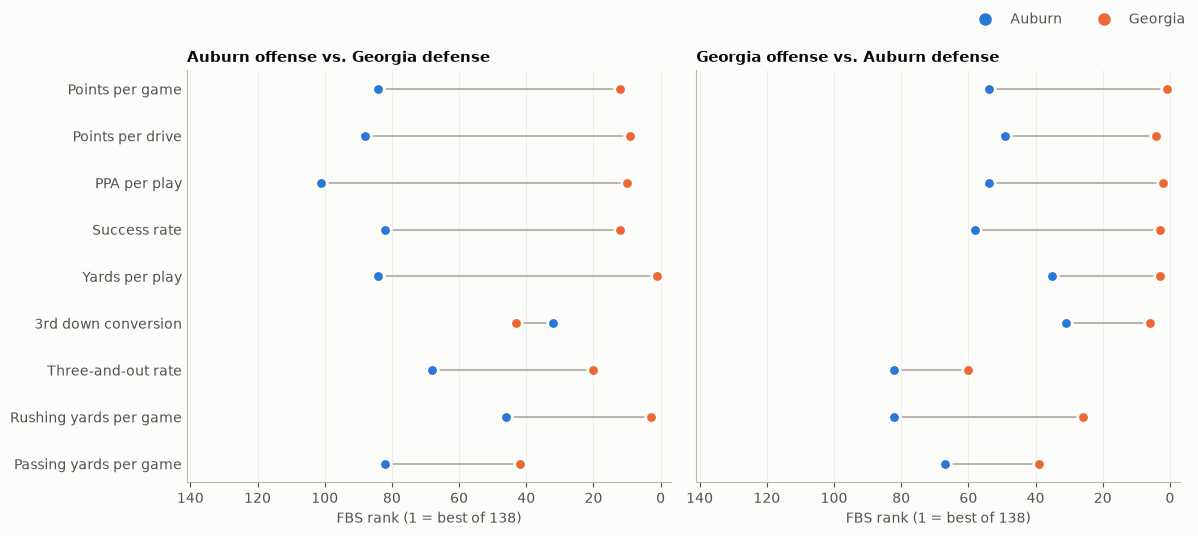

In [10]:
# matchup ranks: each pair of dots is one offense vs. the defense it faces; further right = better
fbs_teams = matchup["fbs_teams"].iloc[0]
metrics = off.index[::-1]          # first metric at the top
y = np.arange(len(metrics))

fig, axes = plt.subplots(1, 2, figsize=(12, 0.42 * len(metrics) + 1.6), sharey=True)
panels = [
    (axes[0], off["team_rank"], dfn["opp_rank"], f"{TEAM} offense vs. {NEXT_OPP} defense", BLUE, ORANGE),
    (axes[1], off["opp_rank"], dfn["team_rank"], f"{NEXT_OPP} offense vs. {TEAM} defense", ORANGE, BLUE),
]
for ax, off_rank, def_rank, title, off_color, def_color in panels:
    o = off_rank.reindex(metrics).to_numpy()
    d = def_rank.reindex(metrics).to_numpy()
    ax.hlines(y, o, d, color=MUTED, linewidth=1.5, zorder=1)
    ax.scatter(o, y, s=70, color=off_color, edgecolor=SURFACE, linewidth=2, zorder=2)
    ax.scatter(d, y, s=70, color=def_color, edgecolor=SURFACE, linewidth=2, zorder=2)
    ax.set_xlim(fbs_teams + 3, -3)   # rank 1 on the right
    ax.set_xlabel(f"FBS rank (1 = best of {fbs_teams})")
    ax.set_title(title, loc="left", fontsize=11)
    ax.grid(axis="x", color=MUTED, alpha=0.3, linewidth=0.5)
    ax.tick_params(axis="y", length=0)

axes[0].set_yticks(y, metrics)
fig.legend(handles=[plt.Line2D([], [], marker="o", linestyle="", color=BLUE, markersize=8),
                    plt.Line2D([], [], marker="o", linestyle="", color=ORANGE, markersize=8)],
           labels=[TEAM, NEXT_OPP], frameon=False, loc="upper right", ncol=2, labelcolor=INK_2)
plt.tight_layout(rect=(0, 0, 1, 0.94))
plt.show()